# State-wise Budget Allocation Analysis: Spending vs Outcomes (India, 2018-2023)

> **IMPORTANT: ILLUSTRATIVE DATA.** The CSV used here (`synthetic_state_data_ILLUSTRATIVE.csv`) is **synthetic**. It is made up to look realistic (e.g. Kerala low IMR and high literacy, Bihar the opposite). **It is not real statistics.** Replace it with your cleaned official data (RBI, NFHS-5, UDISE+, NITI Aayog) before submitting, and re-run the notebook. Do not quote any number printed here as a real finding.

**Columns used:** `state, year, population, health_spend, edu_spend, infra_spend, imr, life_expectancy, literacy, enrolment, dropout, electricity_access, gsdp_pc`

**Units used in this notebook**

| Column | Unit |
|---|---|
| population | lakh (1 lakh = 100,000 people) |
| health_spend, edu_spend, infra_spend | Rs crore (1 crore = 10,000,000) |
| imr | deaths per 1,000 live births |
| life_expectancy | years |
| literacy, enrolment, dropout, electricity_access | percent |
| gsdp_pc | Rs per person per year |

### Data dictionary
| Column | Meaning | Added by |
|---|---|---|
| state, year | State name and year | raw data |
| population | Population (lakh) | raw data |
| health_spend, edu_spend, infra_spend | State spending (Rs crore) | raw data |
| imr, life_expectancy, literacy, enrolment, dropout, electricity_access, gsdp_pc | Outcome and economy indicators | raw data |
| health_pc, edu_pc, infra_pc | Spending per person (Rs) | this notebook |
| edu_index | Education Index 0-100 (PCA) | this notebook |
| efficiency_gap_health | State's average IMR minus the IMR its health spending predicts (negative = better than expected) | this notebook |
| cluster | K-means group of the state (0, 1, 2) | this notebook |

**How to read this notebook:** run cells top to bottom. Every code cell has comments, and every unit starts with a short plain-language explanation.

---
# Unit I: Problem Definition, Data Life Cycle, Analysis vs Analytics

## 1.1 Problem statement
Indian states spend very different amounts on **health, education and infrastructure**. But more spending does not always give better results. 

**Question:** Which states turn their budget into good outcomes, which do not, and how should spending be adjusted?

## 1.2 Objectives
1. Compare per-capita spending across states and years.
2. Measure outcomes (IMR, life expectancy, literacy, enrolment, dropout, electricity access).
3. Test whether spending is related to outcomes.
4. Find efficient and inefficient states.
5. Give recommendations.

## 1.3 Data life cycle (the journey of data)
| Stage | What it means | In this project |
|---|---|---|
| 1. Collection | Getting raw data | Download from RBI, NFHS-5, UDISE+, NITI Aayog |
| 2. Storage | Keeping it safely | CSV file / SQLite database |
| 3. Cleaning | Fixing errors | Fix state names, missing values, outliers |
| 4. Analysis | Finding patterns | EDA, regression, clustering |
| 5. Visualisation | Showing results | Seaborn charts, Power BI dashboard |
| 6. Decision / Action | Using results | Budget recommendations |
| 7. Archive / Delete | Retire data responsibly | Keep a copy, remove personal data |

## 1.4 Data analysis vs data analytics
| | Data **analysis** | Data **analytics** |
|---|---|---|
| Meaning | Examining data to understand **what happened** | Broader process, includes **why, what will happen, what to do** |
| Scope | Smaller, often one dataset | Larger, uses tools, statistics and machine learning |
| Example here | "Kerala's average IMR was 7" | "If health spending rises 10%, IMR may fall by X, so allocate more to state Y" |
| Types | Descriptive | Descriptive, diagnostic, predictive, prescriptive |

**In this case study:** EDA is mostly *analysis*. Regression, random forest and MLP (predicting) and recommendations (prescribing) are *analytics*.

In [1]:
# ---- Imports (libraries we need) ----
import numpy as np                      # numbers and arrays
import pandas as pd                     # tables (DataFrames)
import matplotlib.pyplot as plt         # basic charts
import seaborn as sns                   # prettier statistical charts
import sqlite3                          # small built-in database (for SQL)
import warnings
warnings.filterwarnings("ignore")       # keep the output clean

sns.set_theme(style="whitegrid")        # nicer chart style
pd.set_option("display.max_columns", 30)

## 1.5 Load the data and clean it
We load the raw CSV and fix the problems on purpose hidden in it: **messy state names, missing values and outliers**. If you already have a cleaned CSV, you can skip the cleaning cell and just load it.

In [2]:
# ---- Load the raw file ----
df = pd.read_csv("synthetic_state_data_ILLUSTRATIVE.csv")
raw_df = df.copy()                       # keep the untouched raw data for the cleaning log
print("Raw shape:", df.shape)
print("Missing values before cleaning:", df.isna().sum().sum())
df.head()

Raw shape: (168, 13)
Missing values before cleaning: 12


,state,year,population,health_spend,edu_spend,infra_spend,imr,life_expectancy,literacy,enrolment,dropout,electricity_access,gsdp_pc
0,Andhra Pradesh,2018,520.3,10732.7,28071.7,27324.3,30.5,69.3,67.1,77.8,17.0,99.4,151979.0
1,Andhra Pradesh,2019,526.5,12560.1,31237.0,28571.8,30.2,69.8,67.3,80.0,16.4,99.7,157376.0
2,Andhra Pradesh,2020,532.8,16525.4,30358.9,23599.4,30.0,70.0,68.6,78.7,17.3,99.9,155538.0
3,Andhra Pradesh,2021,536.5,18809.0,37125.5,32069.0,NaN,70.0,69.4,NaN,15.6,100.0,179275.0
4,Andhra Pradesh,2022,543.4,16477.4,40117.1,36278.5,27.9,70.3,69.9,82.7,13.6,100.0,188035.0


In [3]:
# ---- 1) Standardise state names ----
df["state"] = df["state"].str.strip().str.title()        # remove spaces, fix capitals
df["state"] = df["state"].replace({"Orissa": "Odisha", "W. Bengal": "West Bengal"})
print("Number of states:", df["state"].nunique())          # should be 28

# ---- 2) Flag outliers: a value is suspicious if it is >4x or <1/4 of that state's median ----
num_cols = [c for c in df.columns if c not in ("state", "year")]
flagged = 0
for c in num_cols:
    med = df.groupby("state")[c].transform("median")
    ratio = df[c] / med
    bad = (ratio > 4) | (ratio < 1/4)
    flagged += bad.sum()
    df.loc[bad, c] = np.nan                                 # treat them as missing
print("Outliers flagged:", flagged)

# ---- 3) Fill missing values: interpolate along the years within each state ----
df = df.sort_values(["state", "year"]).reset_index(drop=True)
for c in num_cols:
    df[c] = df.groupby("state")[c].transform(lambda s: s.interpolate(limit_direction="both"))
print("Missing values after cleaning:", df.isna().sum().sum())

# ---- Cleaning log: how many cells did we change in each column? ----
raw_sorted = raw_df.copy()
raw_sorted["state"] = raw_sorted["state"].str.strip().str.title().replace({"Orissa": "Odisha", "W. Bengal": "West Bengal"})
raw_sorted = raw_sorted.sort_values(["state", "year"]).reset_index(drop=True)
changed = {c: int((~np.isclose(raw_sorted[c], df[c], equal_nan=True)).sum()) for c in num_cols}
print("Cells changed per column (missing filled + outliers fixed):")
print({k: v for k, v in changed.items() if v > 0})

# ---- 4) Per-capita spending in Rs per person: crore*10^7 / (lakh*10^5) = crore/lakh*100 ----
for sector in ["health", "edu", "infra"]:
    df[f"{sector}_pc"] = df[f"{sector}_spend"] / df["population"] * 100
df.head()

Number of states: 28
Outliers flagged: 4
Missing values after cleaning: 0
Cells changed per column (missing filled + outliers fixed):
{'health_spend': 1, 'infra_spend': 2, 'imr': 4, 'literacy': 3, 'enrolment': 2, 'dropout': 3, 'gsdp_pc': 1}


,state,year,population,health_spend,edu_spend,infra_spend,imr,life_expectancy,literacy,enrolment,dropout,electricity_access,gsdp_pc,health_pc,edu_pc,infra_pc
0,Andhra Pradesh,2018,520.3,10732.7,28071.7,27324.3,30.50,69.3,67.1,77.8,17.0,99.4,151979.0,2062.790698,5395.291178,5251.643283
1,Andhra Pradesh,2019,526.5,12560.1,31237.0,28571.8,30.20,69.8,67.3,80.0,16.4,99.7,157376.0,2385.584046,5932.953466,5426.742640
2,Andhra Pradesh,2020,532.8,16525.4,30358.9,23599.4,30.00,70.0,68.6,78.7,17.3,99.9,155538.0,3101.614114,5697.991742,4429.316817
3,Andhra Pradesh,2021,536.5,18809.0,37125.5,32069.0,28.95,70.0,69.4,80.7,15.6,100.0,179275.0,3505.871389,6919.944082,5977.446412
4,Andhra Pradesh,2022,543.4,16477.4,40117.1,36278.5,27.90,70.3,69.9,82.7,13.6,100.0,188035.0,3032.278248,7382.609496,6676.205374


---
# Unit II: Exploratory Data Analysis (EDA)

EDA means *looking at the data before modelling*: its size, ranges, gaps, shapes and relationships. It prevents silly mistakes later.

In [4]:
# ---- Summary statistics: count, mean, std, min, quartiles, max ----
df.describe().round(1)

,year,population,health_spend,edu_spend,infra_spend,imr,life_expectancy,literacy,enrolment,dropout,electricity_access,gsdp_pc,health_pc,edu_pc,infra_pc
count,168.0,168.0,168.0,168.0,168.0,168.0,168.0,168.0,168.0,168.0,168.0,168.0,168.0,168.0,168.0
mean,2020.5,471.0,12199.1,26652.3,24028.3,23.2,70.2,78.0,85.4,12.5,98.5,195530.9,4041.6,8878.0,7889.8
std,1.7,510.5,10738.9,23297.1,21942.0,12.7,2.6,8.1,9.9,6.4,2.2,126356.0,2270.4,5006.1,4513.5
min,2018.0,7.0,577.3,1477.2,1224.0,2.0,65.5,61.2,65.2,1.0,90.1,44407.0,1416.0,3203.7,2309.7
25%,2019.0,37.7,1931.2,4292.9,3853.0,13.4,68.2,70.6,78.2,7.2,97.6,107443.2,2612.7,5441.6,4862.4
50%,2020.5,355.4,10134.4,22454.6,20120.2,23.0,70.3,77.9,85.4,11.7,99.6,161873.0,3155.9,6898.8,6423.2
75%,2022.0,706.1,18443.6,40793.1,35795.4,34.2,71.7,82.6,93.1,18.1,100.0,244542.8,5047.0,11186.2,9908.5
max,2023.0,2385.5,45468.9,110781.4,113689.3,48.8,76.2,97.4,105.1,25.3,100.0,674230.0,13411.1,32755.4,27800.0


**Read it like this:** `mean` is the average, `std` shows spread, `min`/`max` show extremes. A `max` far above the `75%` value hints at outliers.

In [5]:
# ---- Missing values per column (should be 0 after cleaning) ----
df.isna().sum()

state                 0
year                  0
population            0
health_spend          0
edu_spend             0
infra_spend           0
imr                   0
life_expectancy       0
literacy              0
enrolment             0
dropout               0
electricity_access    0
gsdp_pc               0
health_pc             0
edu_pc                0
infra_pc              0
dtype: int64

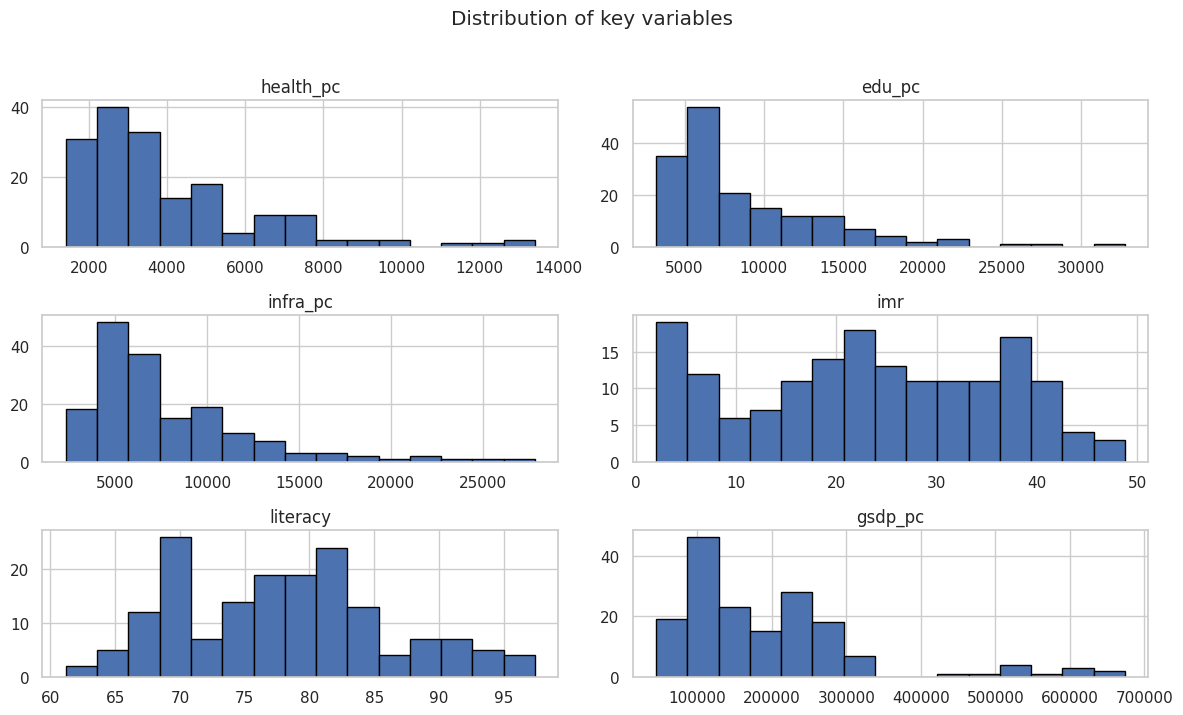

In [6]:
# ---- Histograms: shape of each variable ----
cols = ["health_pc", "edu_pc", "infra_pc", "imr", "literacy", "gsdp_pc"]
df[cols].hist(bins=15, figsize=(12, 7), edgecolor="black")
plt.suptitle("Distribution of key variables", y=1.02)
plt.tight_layout(); plt.show()

A **histogram** shows how often values fall in each range. A long tail to the right (common in spending and GSDP) means a few rich states pull the average up.

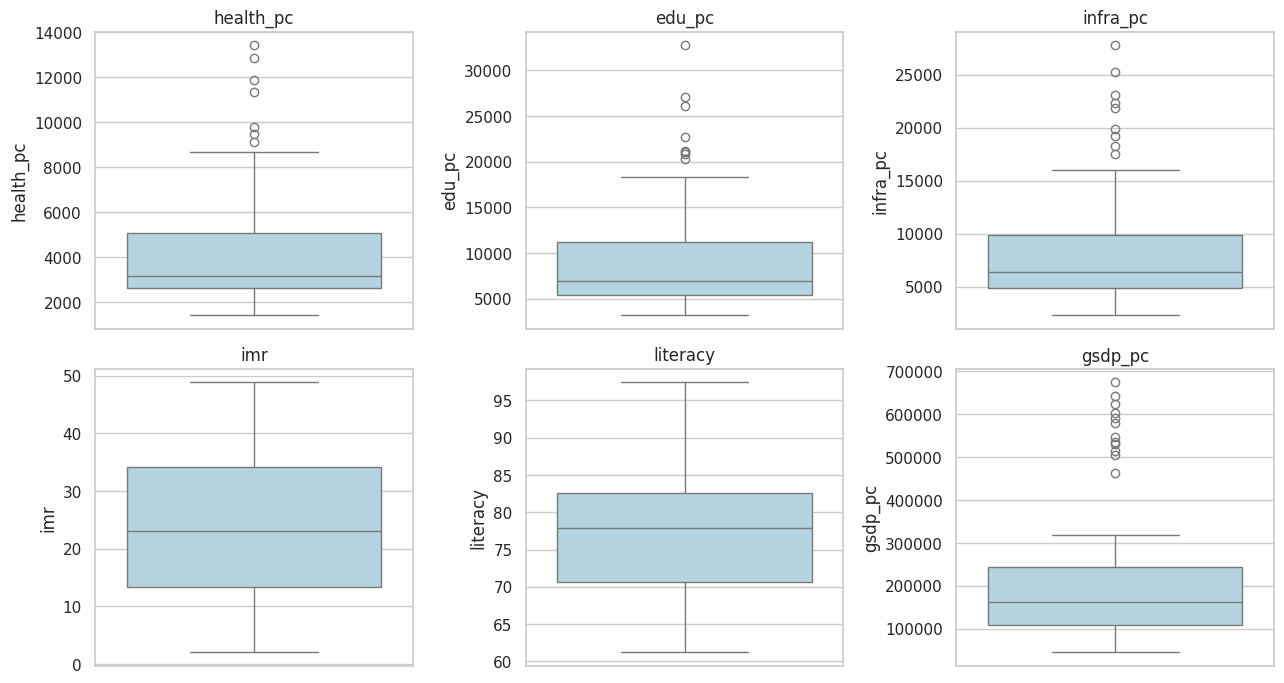

In [7]:
# ---- Box plots: median, spread and outliers ----
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), cols):
    sns.boxplot(y=df[c], ax=ax, color="lightblue")
    ax.set_title(c)
plt.tight_layout(); plt.show()

The **box** holds the middle 50% of values, the line is the median, and dots beyond the whiskers are potential outliers.

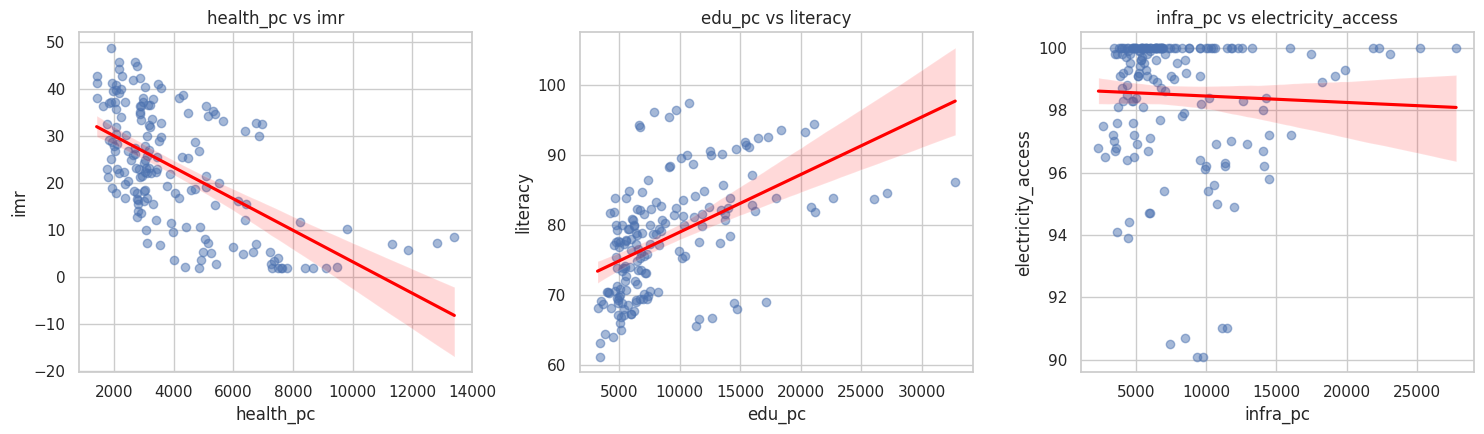

In [8]:
# ---- Scatter plots: spending vs outcome ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
pairs = [("health_pc", "imr"), ("edu_pc", "literacy"), ("infra_pc", "electricity_access")]
for ax, (x, y) in zip(axes, pairs):
    sns.regplot(data=df, x=x, y=y, ax=ax, scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
    ax.set_title(f"{x} vs {y}")
plt.tight_layout(); plt.show()

Each dot is one state in one year. The red line is the trend. **Downward** line for IMR means more spending goes with lower infant deaths; **upward** lines for literacy and electricity mean better outcomes. A weak slope means a weak link.

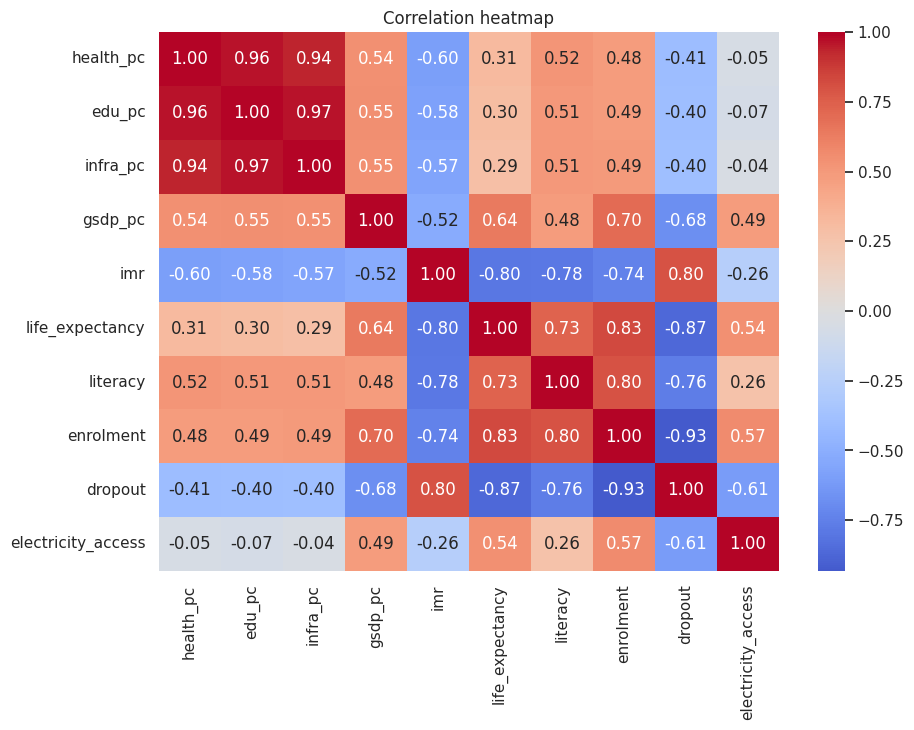

In [9]:
# ---- Correlation heatmap ----
corr_cols = ["health_pc", "edu_pc", "infra_pc", "gsdp_pc", "imr", "life_expectancy",
             "literacy", "enrolment", "dropout", "electricity_access"]
plt.figure(figsize=(10, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

**Correlation** (r) runs from -1 to +1. Near +1: both rise together. Near -1: one rises as the other falls. Near 0: no straight-line relationship.
Careful: **correlation is not causation.** GSDP per capita can drive both spending and outcomes at the same time.

### SQL with sqlite3: state-wise averages

In [10]:
# ---- Put the DataFrame into an in-memory SQLite database, then query with SQL ----
conn = sqlite3.connect(":memory:")
df.to_sql("state_data", conn, index=False, if_exists="replace")

query = '''
SELECT  state,
        ROUND(AVG(health_pc), 0)          AS avg_health_pc,
        ROUND(AVG(edu_pc), 0)             AS avg_edu_pc,
        ROUND(AVG(infra_pc), 0)           AS avg_infra_pc,
        ROUND(AVG(imr), 1)                AS avg_imr,
        ROUND(AVG(literacy), 1)           AS avg_literacy
FROM    state_data
GROUP BY state
ORDER BY avg_imr ASC;
'''
state_avg_sql = pd.read_sql(query, conn)
state_avg_sql.head(10)

,state,avg_health_pc,avg_edu_pc,avg_infra_pc,avg_imr,avg_literacy
0,Mizoram,8207.0,17762.0,16380.0,2.6,92.6
1,Nagaland,6819.0,14899.0,11994.0,2.7,81.8
2,Kerala,4128.0,8465.0,7962.0,4.3,95.6
3,Goa,6614.0,14213.0,12137.0,4.6,90.7
4,Manipur,5648.0,12466.0,11430.0,7.9,81.8
5,Sikkim,11242.0,25096.0,22972.0,8.4,83.8
6,Tamil Nadu,3251.0,7106.0,5920.0,12.1,81.7
7,Himachal Pradesh,5500.0,12109.0,10632.0,15.9,84.6
8,Maharashtra,2552.0,5281.0,5032.0,16.1,83.5
9,Punjab,3193.0,7148.0,5993.0,18.6,77.7


`GROUP BY state` makes one row per state, `AVG()` averages across years, `ORDER BY ... ASC` sorts best IMR (lowest) first.

### Equivalent code in R
Run this in RStudio (it is not executed here). Put the CSV in your working directory.
```r
library(dplyr)
library(ggplot2)
library(corrplot)

df <- read.csv("synthetic_state_data_ILLUSTRATIVE.csv")

# Per-capita spending (Rs per person)
df$health_pc <- df$health_spend / df$population * 100
df$edu_pc    <- df$edu_spend    / df$population * 100
df$infra_pc  <- df$infra_spend  / df$population * 100

summary(df)                       # like df.describe()
colSums(is.na(df))                # missing values per column

hist(df$imr, breaks = 15, main = "IMR", col = "lightblue")   # histogram
boxplot(df$literacy, main = "Literacy")                      # box plot
plot(df$health_pc, df$imr, xlab = "Health per capita", ylab = "IMR")  # scatter

# Correlation heatmap
num <- df[, c("health_pc","edu_pc","infra_pc","gsdp_pc","imr","literacy","enrolment","dropout")]
corrplot(cor(num, use = "complete.obs"), method = "color", addCoef.col = "black")

# State-wise averages (same as the SQL query)
state_avg <- df %>%
  group_by(state) %>%
  summarise(avg_health_pc = mean(health_pc, na.rm = TRUE),
            avg_imr = mean(imr, na.rm = TRUE),
            avg_literacy = mean(literacy, na.rm = TRUE)) %>%
  arrange(avg_imr)
```

---
# Unit III: Machine Learning Models

**Plan:** use spending (and GSDP) to predict outcomes.
- **Features (X, inputs):** `health_pc, edu_pc, infra_pc, gsdp_pc`
- **Targets (y, outputs):** `imr` and `literacy`

**Key ideas for beginners**
- **Train/test split:** hide 20% of the data. Train on 80%, test on the hidden 20%, to check the model works on unseen data.
- **R²:** share of variation explained (1 = perfect, 0 = no better than guessing the average, can be negative).
- **RMSE:** typical size of the prediction error, in the same unit as the target (lower is better).
- **Cross-validation (CV):** repeat train/test several times on different parts and average the score, which is more reliable than one split.

In [11]:
from sklearn.model_selection import train_test_split, cross_val_score, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error

features = ["health_pc", "edu_pc", "infra_pc", "gsdp_pc"]
X = df[features]

def evaluate(model, target, name):
    '''Train on 80%, test on 20%, print R2 and RMSE, plus 5-fold cross-validation R2.'''
    y = df[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    # Cross-validation: GroupKFold keeps all years of a state together,
    # so the model is tested on states it has never seen (more honest).
    cv = cross_val_score(model, X, y, cv=GroupKFold(n_splits=5), groups=df["state"], scoring="r2")
    print(f"{name:<22} target={target:<9} Test R2={r2:6.3f}  RMSE={rmse:7.3f}  CV R2={cv.mean():6.3f}")
    return {"model": name, "target": target, "R2": r2, "RMSE": rmse, "CV_R2": cv.mean()}

## 3.1 Linear regression
Fits a straight line: `target = b0 + b1*health_pc + b2*edu_pc + ...`. The coefficients show how much the target changes when one input rises by 1 unit, others fixed.

In [12]:
results = []
results.append(evaluate(make_pipeline(StandardScaler(), LinearRegression()), "imr", "Linear Regression"))
results.append(evaluate(make_pipeline(StandardScaler(), LinearRegression()), "literacy", "Linear Regression"))

# Look at the coefficients (inputs were standardised, so sizes are comparable)
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X, df["imr"])
print("\nIMR coefficients (per 1 std-dev change):")
print(pd.Series(lin[-1].coef_, index=features).round(2))

Linear Regression      target=imr       Test R2= 0.421  RMSE= 10.221  CV R2= 0.042
Linear Regression      target=literacy  Test R2= 0.419  RMSE=  6.060  CV R2= 0.046

IMR coefficients (per 1 std-dev change):
health_pc   -6.60
edu_pc       0.80
infra_pc     0.19
gsdp_pc     -3.58
dtype: float64


## 3.2 Ridge and Lasso (regularisation)
When inputs are correlated (spending and GSDP move together), plain regression can give unstable coefficients.
- **Ridge** shrinks all coefficients (penalty on their squares).
- **Lasso** can shrink some to exactly **zero**, so it also does feature selection.
`alpha` controls the penalty strength.

In [13]:
for target in ["imr", "literacy"]:
    results.append(evaluate(make_pipeline(StandardScaler(), Ridge(alpha=1.0)), target, "Ridge"))
    results.append(evaluate(make_pipeline(StandardScaler(), Lasso(alpha=0.5)), target, "Lasso"))

lasso = make_pipeline(StandardScaler(), Lasso(alpha=0.5)).fit(X, df["imr"])
print("\nLasso coefficients for IMR (zero = feature dropped):")
print(pd.Series(lasso[-1].coef_, index=features).round(2))

Ridge                  target=imr       Test R2= 0.418  RMSE= 10.245  CV R2= 0.046
Lasso                  target=imr       Test R2= 0.401  RMSE= 10.393  CV R2= 0.094
Ridge                  target=literacy  Test R2= 0.416  RMSE=  6.077  CV R2= 0.051
Lasso                  target=literacy  Test R2= 0.381  RMSE=  6.257  CV R2= 0.090

Lasso coefficients for IMR (zero = feature dropped):
health_pc   -5.35
edu_pc      -0.00
infra_pc    -0.00
gsdp_pc     -3.20
dtype: float64


## 3.3 Decision tree
Asks a series of yes/no questions (e.g. "is GSDP per capita above 1.5 lakh?") to split the data. Easy to explain, but a deep tree can **overfit** (memorise the training data), so we limit `max_depth`.

In [14]:
for target in ["imr", "literacy"]:
    results.append(evaluate(DecisionTreeRegressor(max_depth=4, random_state=42), target, "Decision Tree"))

Decision Tree          target=imr       Test R2= 0.640  RMSE=  8.062  CV R2= 0.053
Decision Tree          target=literacy  Test R2= 0.557  RMSE=  5.295  CV R2=-0.581


## 3.4 Random forest and feature importance
Builds many trees on random parts of the data and **averages** them, which is usually more accurate and stable than one tree. **Feature importance** tells which inputs the forest relied on most.

Random Forest          target=imr       Test R2= 0.670  RMSE=  7.713  CV R2= 0.232


Random Forest          target=literacy  Test R2= 0.614  RMSE=  4.938  CV R2=-0.026


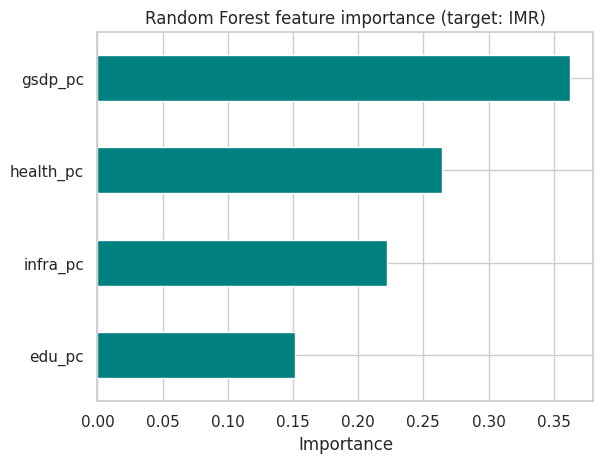

In [15]:
for target in ["imr", "literacy"]:
    results.append(evaluate(RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42), target, "Random Forest"))

rf = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42).fit(X, df["imr"])
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", color="teal", title="Random Forest feature importance (target: IMR)")
plt.xlabel("Importance"); plt.show()

A higher bar means the feature helped the forest predict IMR more. Importance shows **usefulness for prediction**, not cause and effect.

## 3.5 Support Vector Machine (RBF kernel)
SVR finds a smooth curve that fits most points within a small error band. The **RBF kernel** lets it bend, so it can capture non-linear patterns. **Scaling is essential** for SVM, so we use `StandardScaler`. `C` controls how strictly errors are punished, `gamma` controls how "wiggly" the curve is.

In [16]:
for target in ["imr", "literacy"]:
    results.append(evaluate(make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, gamma="scale")), target, "SVM (RBF)"))

SVM (RBF)              target=imr       Test R2= 0.635  RMSE=  8.109  CV R2= 0.278
SVM (RBF)              target=literacy  Test R2= 0.557  RMSE=  5.291  CV R2= 0.240


In [17]:
# ---- Compare all models ----
res = pd.DataFrame(results).round(3)
res.pivot(index="model", columns="target", values=["R2", "RMSE", "CV_R2"])

R2             RMSE           CV_R2         
target               imr literacy     imr literacy    imr literacy
model                                                             
Decision Tree      0.640    0.557   8.062    5.295  0.053   -0.581
Lasso              0.401    0.381  10.393    6.257  0.094    0.090
Linear Regression  0.421    0.419  10.221    6.060  0.042    0.046
Random Forest      0.670    0.614   7.713    4.938  0.232   -0.026
Ridge              0.418    0.416  10.245    6.077  0.046    0.051
SVM (RBF)          0.635    0.557   8.109    5.291  0.278    0.240

Compare **Test R²** with **CV R²**. If test R² is high but CV R² is low, the model is overfitting or memorising states. Pick the model with good, stable CV R².

## 3.6 K-means clustering of states
Groups similar states automatically (no target needed). We cluster each state's **average** spending and outcomes. We choose `k` using the **silhouette score** (higher = better-separated groups).

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

cl_cols = ["health_pc", "edu_pc", "infra_pc", "gsdp_pc", "imr", "literacy", "electricity_access"]
state_mean = df.groupby("state")[cl_cols].mean()
Z = StandardScaler().fit_transform(state_mean)          # put all columns on the same scale

for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z)
    print(f"k={k}  silhouette={silhouette_score(Z, labels):.3f}")

k=2  silhouette=0.399
k=3  silhouette=0.299
k=4  silhouette=0.340
k=5  silhouette=0.339
k=6  silhouette=0.333


         health_pc   edu_pc  infra_pc   gsdp_pc   imr  literacy  \
cluster                                                           
0           8220.7  17992.8   15870.7  354632.2   4.6      87.2   
1           3074.7   6815.4    6075.0  114318.4  35.9      70.7   
2           3573.8   7818.7    6969.8  215294.8  18.2      81.4   

         electricity_access  
cluster                      
0                      98.5  
1                      97.2  
2                      99.6  

Cluster 0: Goa, Mizoram, Nagaland, Sikkim

Cluster 1: Andhra Pradesh, Arunachal Pradesh, Assam, Bihar, Chhattisgarh, Jharkhand, Madhya Pradesh, Meghalaya, Odisha, Rajasthan, Uttar Pradesh

Cluster 2: Gujarat, Haryana, Himachal Pradesh, Karnataka, Kerala, Maharashtra, Manipur, Punjab, Tamil Nadu, Telangana, Tripura, Uttarakhand, West Bengal


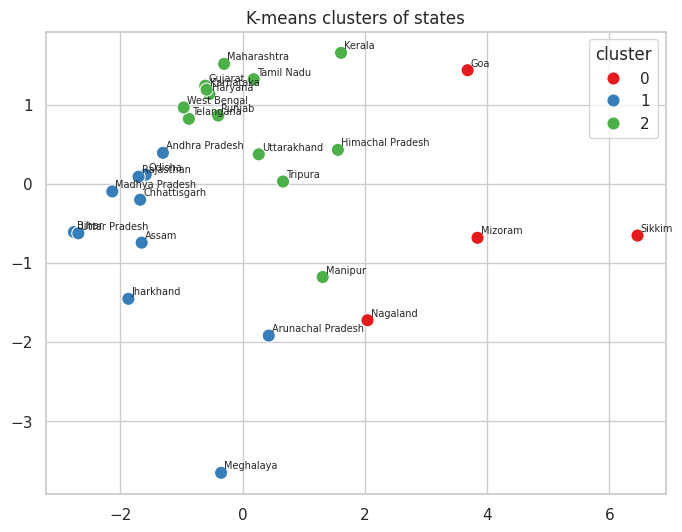

In [19]:
k = 3   # choose using the silhouette scores above (and common sense)
state_mean["cluster"] = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z)

# Profile each cluster: what do its states look like on average?
print(state_mean.groupby("cluster").mean().round(1))
for c in sorted(state_mean["cluster"].unique()):
    print(f"\nCluster {c}:", ", ".join(state_mean.index[state_mean['cluster'] == c]))

# Draw the clusters in 2D using PCA just for plotting
xy = PCA(n_components=2).fit_transform(Z)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=state_mean["cluster"], palette="Set1", s=90)
for i, name in enumerate(state_mean.index):
    plt.text(xy[i, 0] + 0.05, xy[i, 1] + 0.05, name, fontsize=7)
plt.title("K-means clusters of states"); plt.show()

Name each cluster from its averages, for example: *high spend, strong outcomes* / *low spend, weak outcomes* / *small hill states with high spend*. These labels are your interpretation.

## 3.7 PCA to build an "education index"
**PCA (Principal Component Analysis)** squeezes several related columns into one score that keeps most of the information. Here we combine four education columns into a single **Education Index (0 to 100)**. Dropout is reversed (`100 - dropout`) so that higher always means better.

In [20]:
edu_df = pd.DataFrame({
    "literacy": df["literacy"],
    "enrolment": df["enrolment"],
    "retention": 100 - df["dropout"],     # higher = better
    "edu_pc": df["edu_pc"],
})
Z_edu = StandardScaler().fit_transform(edu_df)

pca = PCA(n_components=1)
score = pca.fit_transform(Z_edu).ravel()

# PCA direction is arbitrary, so make sure higher score = better education
if np.corrcoef(score, df["literacy"])[0, 1] < 0:
    score = -score

df["edu_index"] = (score - score.min()) / (score.max() - score.min()) * 100   # scale 0-100
print("Variance explained by the index:", round(pca.explained_variance_ratio_[0] * 100, 1), "%")
print("Loadings:", dict(zip(edu_df.columns, pca.components_[0].round(2))))

print("\nTop 5 states by Education Index (2023):")
print(df[df.year == 2023].nlargest(5, "edu_index")[["state", "edu_index"]].round(1).to_string(index=False))
print("\nBottom 5 states by Education Index (2023):")
print(df[df.year == 2023].nsmallest(5, "edu_index")[["state", "edu_index"]].round(1).to_string(index=False))

Variance explained by the index: 74.9 %
Loadings: {'literacy': np.float64(0.52), 'enrolment': np.float64(0.55), 'retention': np.float64(0.53), 'edu_pc': np.float64(0.38)}

Top 5 states by Education Index (2023):
           state  edu_index
          Sikkim      100.0
             Goa       92.5
          Kerala       87.6
Himachal Pradesh       85.3
         Mizoram       85.1

Bottom 5 states by Education Index (2023):
         state  edu_index
         Bihar       10.9
 Uttar Pradesh       21.9
     Jharkhand       22.2
Madhya Pradesh       27.0
  Chhattisgarh       33.4


## 3.8 Which states use money efficiently? (residual analysis)
Fit a line between spending and outcome. A state **better than the line predicts** is efficient; **worse than predicted** is inefficient. We use state averages for 2018-2023 and control for nothing else, so treat it as a first screening, not proof.

In [21]:
sm = df.groupby("state")[["health_pc", "gsdp_pc", "imr"]].mean()
# Regress IMR on health spending (state-level averages)
slope, intercept = np.polyfit(sm["health_pc"], sm["imr"], 1)
sm["expected_imr"] = intercept + slope * sm["health_pc"]
sm["gap"] = sm["imr"] - sm["expected_imr"]        # negative gap = better than expected

print("More efficient on health (IMR lower than spending predicts):")
print(sm.nsmallest(5, "gap")[["health_pc", "imr", "expected_imr", "gap"]].round(1))
print("\nLess efficient on health (IMR higher than spending predicts):")
print(sm.nlargest(5, "gap")[["health_pc", "imr", "expected_imr", "gap"]].round(1))

More efficient on health (IMR lower than spending predicts):
             health_pc   imr  expected_imr   gap
state                                           
Kerala          4128.4   4.3          22.9 -18.6
Tamil Nadu      3250.6  12.1          26.0 -13.9
Maharashtra     2551.8  16.1          28.5 -12.4
Nagaland        6819.5   2.7          13.4 -10.7
Manipur         5648.0   7.9          17.5  -9.7

Less efficient on health (IMR higher than spending predicts):
                   health_pc   imr  expected_imr   gap
state                                                 
Arunachal Pradesh     6106.2  32.6          15.9  16.7
Madhya Pradesh        2512.1  44.9          28.6  16.3
Meghalaya             4981.7  36.1          19.9  16.2
Assam                 2908.9  41.2          27.2  14.0
Sikkim               11241.8   8.4          -2.2  10.6


---
# Unit IV: Neural Network (MLP)

An **MLP (Multi-Layer Perceptron)** is a small neural network: inputs -> hidden layers of "neurons" -> output.

**Key concepts in simple words**
- **Neuron:** takes inputs, multiplies each by a **weight**, adds a **bias**, then passes the sum through an activation function.
- **Activation function:** adds non-linearity so the network can learn curves. Common ones: **ReLU** (`max(0, x)`), tanh, sigmoid. Without activation, the network would just be linear regression.
- **Loss function:** a number saying how wrong the predictions are (here: mean squared error).
- **Gradient descent:** repeatedly nudge each weight a little in the direction that reduces the loss, like walking downhill in fog. The step size is the **learning rate**.
- **Backpropagation:** the method that efficiently works out *how much each weight contributed to the error* (using the chain rule, moving backwards from output to input), so gradient descent knows which way to nudge.
- **Epoch:** one full pass over the training data.

**Hyper-parameters** (settings you choose, not learned): number of hidden layers and neurons, activation, learning rate, number of epochs, batch size, regularisation (`alpha`), early stopping.

MLP Test R2  : 0.421
MLP Test RMSE: 10.222


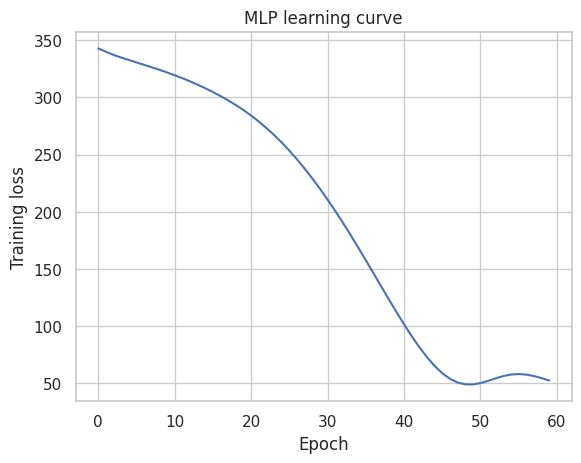

In [22]:
from sklearn.neural_network import MLPRegressor

y = df["imr"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling matters a lot for neural networks
mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(16, 8),   # two hidden layers: 16 and 8 neurons
                 activation="relu",            # activation function
                 solver="adam",                # a smart version of gradient descent
                 learning_rate_init=0.01,      # step size
                 alpha=0.001,                  # regularisation strength
                 max_iter=1000,                # max epochs
                 early_stopping=True,          # stop when validation score stops improving
                 random_state=42)
)
mlp.fit(X_train, y_train)

pred = mlp.predict(X_test)
print("MLP Test R2  :", round(r2_score(y_test, pred), 3))
print("MLP Test RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))

# Plot the loss curve: it should go down as the network learns
plt.plot(mlp[-1].loss_curve_)
plt.xlabel("Epoch"); plt.ylabel("Training loss"); plt.title("MLP learning curve")
plt.show()

**Reading the result:** with only ~168 rows, a neural network has little data to learn from, and simple models (linear regression, random forest) often do as well or better. Say this honestly in your report: *more complex is not always better.*

(If your course uses Keras: `Sequential([Dense(16, activation="relu"), Dense(8, activation="relu"), Dense(1)])`, compile with `optimizer="adam", loss="mse"`, then `model.fit(...)`. The ideas are identical.)

### Future extension: Reinforcement Learning (RL) for budget allocation
In RL, an **agent** takes **actions**, gets **rewards**, and learns a **policy**. For budgets:
- **State:** a state's current outcomes, spending and GSDP.
- **Action:** how to split next year's budget among health, education and infrastructure.
- **Reward:** improvement in an outcome index (e.g. lower IMR, higher literacy).
- **Policy:** the rule that maps state to action.
This needs far more data and a realistic simulator of how spending affects outcomes, with time lags. It is a **future scope**, not something this dataset can support.

---
# Unit V: Data Visualisation

## 5.1 Seaborn charts

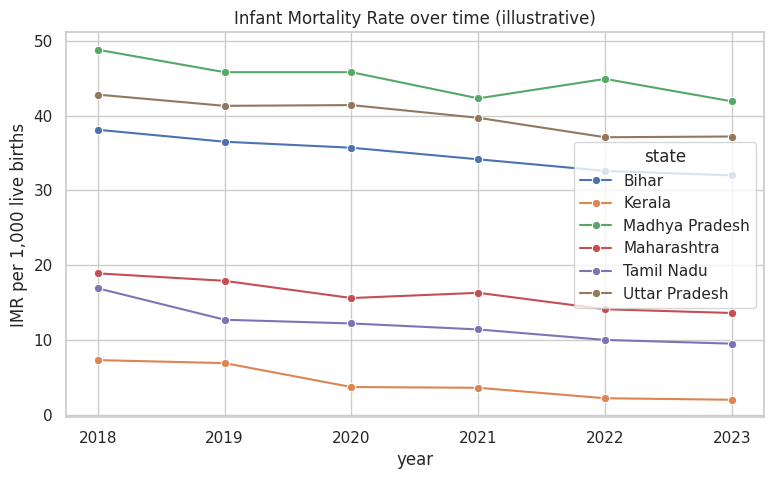

In [23]:
# 1) Trend: IMR over time for selected states
sel = ["Kerala", "Tamil Nadu", "Maharashtra", "Bihar", "Uttar Pradesh", "Madhya Pradesh"]
plt.figure(figsize=(9, 5))
sns.lineplot(data=df[df.state.isin(sel)], x="year", y="imr", hue="state", marker="o")
plt.title("Infant Mortality Rate over time (illustrative)")
plt.ylabel("IMR per 1,000 live births"); plt.show()

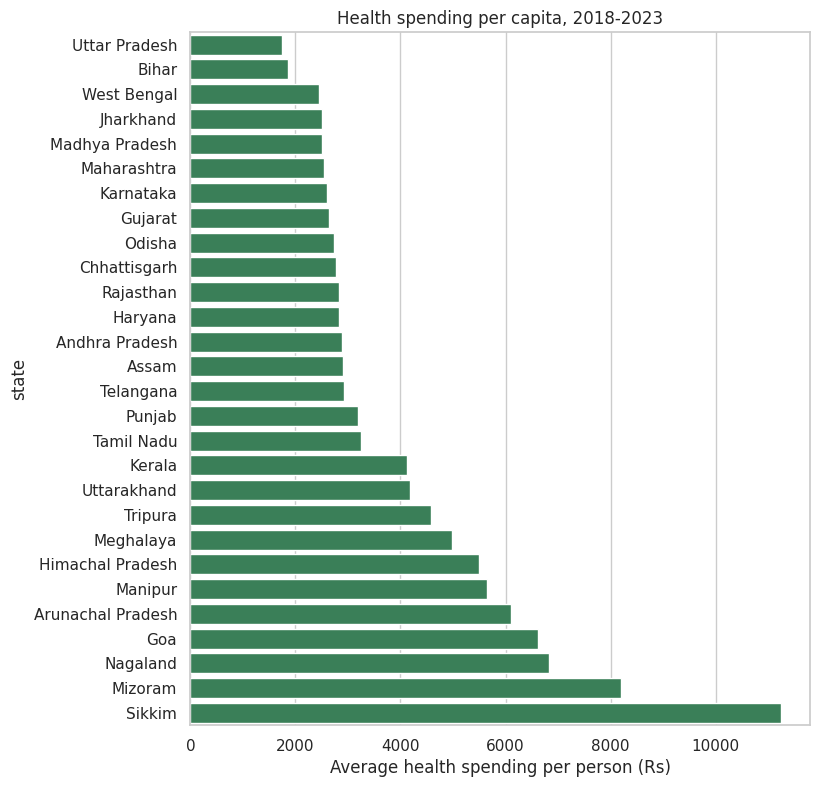

In [24]:
# 2) Bar chart: average per-capita health spending by state (top and bottom 10 together)
avg = df.groupby("state")["health_pc"].mean().sort_values()
plt.figure(figsize=(8, 9))
sns.barplot(x=avg.values, y=avg.index, color="seagreen")
plt.xlabel("Average health spending per person (Rs)"); plt.title("Health spending per capita, 2018-2023")
plt.show()

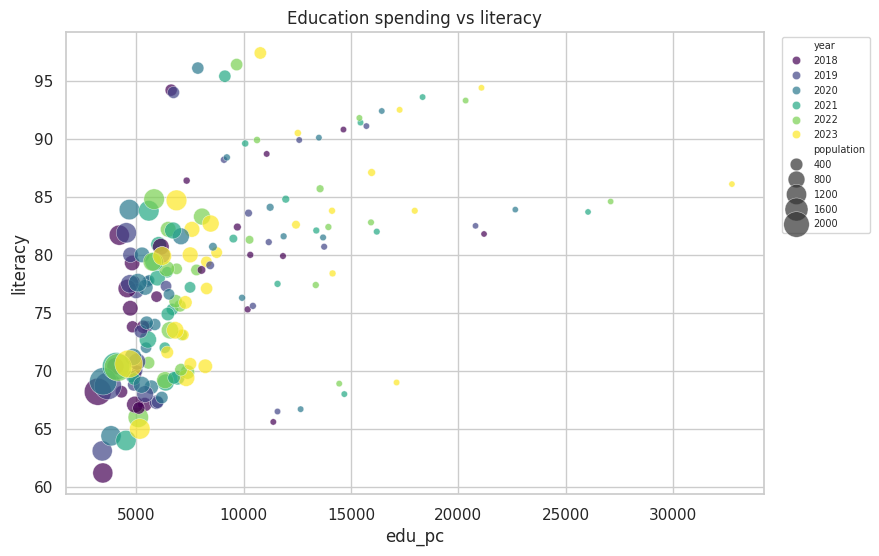

In [25]:
# 3) Scatter with bubble size = population and colour = year
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="edu_pc", y="literacy", size="population", hue="year",
                sizes=(20, 400), palette="viridis", alpha=0.7)
plt.title("Education spending vs literacy"); plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
plt.show()

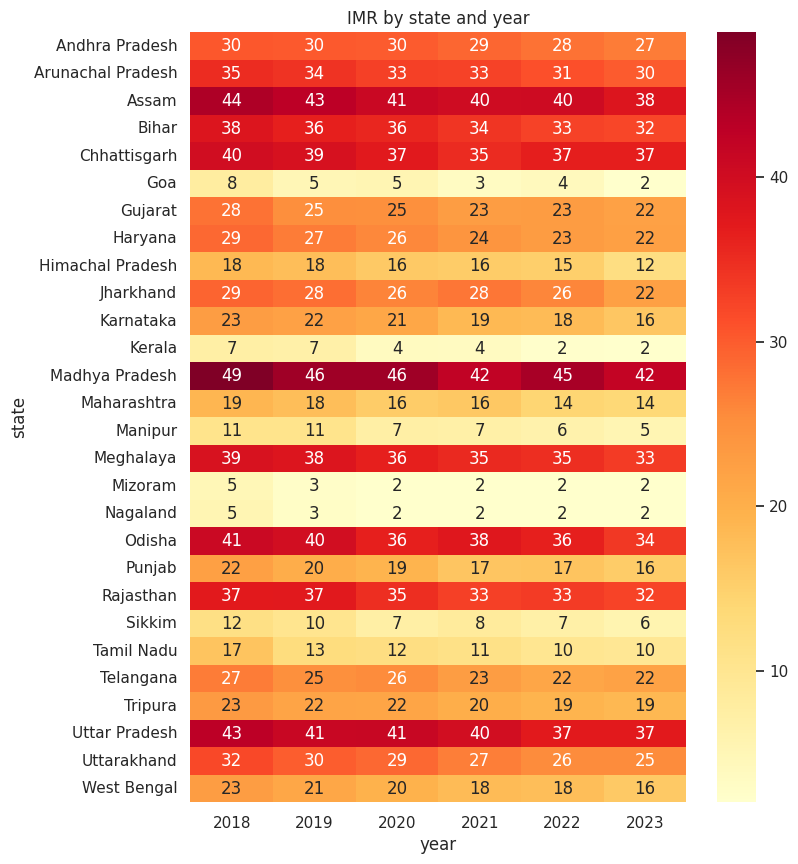

In [26]:
# 4) Heatmap: IMR by state and year
pivot = df.pivot(index="state", columns="year", values="imr")
plt.figure(figsize=(8, 10))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("IMR by state and year"); plt.show()

## 5.2 ggplot2 code in R (run in RStudio)
```r
library(ggplot2)

# Scatter + trend line: spending vs outcome
ggplot(df, aes(x = health_pc, y = imr)) +
  geom_point(aes(color = factor(year)), alpha = 0.7) +
  geom_smooth(method = "lm", color = "red") +
  labs(title = "Health spending vs IMR", x = "Health spending per capita (Rs)",
       y = "IMR per 1,000 live births", color = "Year") +
  theme_minimal()

# Line chart for selected states
sel <- c("Kerala", "Bihar", "Tamil Nadu", "Uttar Pradesh")
ggplot(subset(df, state %in% sel), aes(x = year, y = imr, color = state)) +
  geom_line(linewidth = 1) + geom_point() +
  labs(title = "IMR over time") + theme_minimal()

# Bar chart of average literacy by state
avg <- aggregate(literacy ~ state, df, mean)
ggplot(avg, aes(x = reorder(state, literacy), y = literacy)) +
  geom_col(fill = "steelblue") + coord_flip() +
  labs(x = "State", y = "Average literacy (%)") + theme_minimal()

# Faceted view: one panel per sector
ggplot(df, aes(x = edu_pc, y = literacy)) + geom_point() + facet_wrap(~ year)
```

## 5.3 Power BI / Tableau dashboard plan
**Data:** load the cleaned CSV (`state_data_clean.csv`, created at the end of this unit, already contains per-capita spending, education index, efficiency gap and cluster). Add a state-code or lat/long column if the map does not recognise names.

| Element | Chart type | Fields |
|---|---|---|
| **Map** (main visual) | Filled map (choropleth) | Location = state, colour = selected outcome (IMR / literacy / electricity) |
| **Year slider** | Slicer (single value or range) | `year`, filters every visual |
| **Spending vs outcome** | Scatter plot | X = per-capita spending, Y = outcome, size = population, tooltip = state |
| **Trend** | Line chart | `year` vs outcome, legend = state (selected states) |
| **Top/bottom ranking** | Bar chart with Top-N filter | state vs education index / IMR |
| **KPI cards** | Cards | National average IMR, literacy, average health spend per person |
| **Efficiency table** | Table with conditional colours | state, spending, outcome, efficiency gap |

**Interactivity:** a drop-down parameter to switch sector (Health / Education / Infrastructure), cross-filtering (click a state on the map to update all charts), tooltips.
**Layout tip:** filters on the left, map top-centre, KPI cards on top, scatter and trends below. Use one colour scale (red = worse, green = better) consistently.

In [27]:
# ---- Add state-level results to every row, then save ONE updated CSV for Power BI / Tableau ----
df["efficiency_gap_health"] = df["state"].map(sm["gap"]).round(2)     # from section 3.8
df["cluster"] = df["state"].map(state_mean["cluster"])                # from section 3.6
df["edu_index"] = df["edu_index"].round(1)
for c in ["health_pc", "edu_pc", "infra_pc"]:
    df[c] = df[c].round(0)

df.to_csv("state_data_clean.csv", index=False)
print("Saved state_data_clean.csv:", df.shape[0], "rows x", df.shape[1], "columns")
print("Columns:", list(df.columns))
df.head()

Saved state_data_clean.csv: 168 rows x 19 columns
Columns: ['state', 'year', 'population', 'health_spend', 'edu_spend', 'infra_spend', 'imr', 'life_expectancy', 'literacy', 'enrolment', 'dropout', 'electricity_access', 'gsdp_pc', 'health_pc', 'edu_pc', 'infra_pc', 'edu_index', 'efficiency_gap_health', 'cluster']


,state,year,population,health_spend,edu_spend,infra_spend,imr,life_expectancy,literacy,enrolment,dropout,electricity_access,gsdp_pc,health_pc,edu_pc,infra_pc,edu_index,efficiency_gap_health,cluster
0,Andhra Pradesh,2018,520.3,10732.7,28071.7,27324.3,30.50,69.3,67.1,77.8,17.0,99.4,151979.0,2063.0,5395.0,5252.0,23.8,1.78,1
1,Andhra Pradesh,2019,526.5,12560.1,31237.0,28571.8,30.20,69.8,67.3,80.0,16.4,99.7,157376.0,2386.0,5933.0,5427.0,26.8,1.78,1
2,Andhra Pradesh,2020,532.8,16525.4,30358.9,23599.4,30.00,70.0,68.6,78.7,17.3,99.9,155538.0,3102.0,5698.0,4429.0,25.7,1.78,1
3,Andhra Pradesh,2021,536.5,18809.0,37125.5,32069.0,28.95,70.0,69.4,80.7,15.6,100.0,179275.0,3506.0,6920.0,5977.0,30.8,1.78,1
4,Andhra Pradesh,2022,543.4,16477.4,40117.1,36278.5,27.90,70.3,69.9,82.7,13.6,100.0,188035.0,3032.0,7383.0,6676.0,35.3,1.78,1


---
# Unit VI: Ethics, Privacy, Bias, Limitations and Recommendations

## 6.1 Ethics and privacy
- **No personal data here:** this uses aggregated state-level data, so individual privacy is not at risk. With household or patient data, you would need consent, anonymisation and secure storage (see India's Digital Personal Data Protection Act, 2023).
- **Be honest about data:** state where the data came from, its year, and every cleaning step (here: how missing values and outliers were handled).
- **Neutral framing:** present patterns, not blame on any party or government.
- **Responsible use:** results can influence funding for real people. Wrong or biased conclusions can harm under-served regions.

## 6.2 Bias
- **Data bias:** states with weaker reporting systems may have less accurate numbers (e.g. IMR from small surveys).
- **Selection bias:** analysing only 28 states leaves out Union Territories.
- **Aggregation bias (ecological fallacy):** state averages hide big differences between districts, rural and urban areas, and social groups.
- **Model bias:** algorithms learn from past patterns, which may repeat past inequality if used blindly to allocate money.

## 6.3 Limitations
- **Correlation is not causation.** Spending and outcomes may both depend on GSDP, governance, geography or history.
- **Time lag:** health or school spending takes years to show results. Same-year comparisons can understate impact (use lagged spending in future work).
- **Small sample:** 28 states x 6 years = 168 rows, and rows of the same state are not independent. Complex models overfit easily.
- **Missing spending:** central-scheme money spent in a state may not appear in the state budget.
- **Survey data gaps:** some outcomes (NFHS) are not measured every year.
- **Synthetic data:** results here are illustrative only.

## 6.4 Recommendations (template, fill with your real findings)
1. **Target low-spend, low-outcome states** first for extra allocation.
2. **For high-spend, low-outcome states, fix delivery, not just the amount:** monitoring, fund utilisation, staffing.
3. **Learn from efficient states:** study and share their practices.
4. **Link future budgets partly to outcomes** and publish them.
5. **Improve data:** annual, district-level, standardised reporting.

In [28]:
# ---- Auto-generated key numbers for your summary ----
best_imr = df[df.year == 2023].nsmallest(3, "imr")["state"].tolist()
worst_imr = df[df.year == 2023].nlargest(3, "imr")["state"].tolist()
r_h, r_e, r_i = (df["health_pc"].corr(df["imr"]), df["edu_pc"].corr(df["literacy"]),
                 df["infra_pc"].corr(df["electricity_access"]))
gdp_h = df["gsdp_pc"].corr(df["health_pc"])
print("Lowest IMR in 2023  :", best_imr)
print("Highest IMR in 2023 :", worst_imr)
print(f"Correlation health_pc vs IMR            : {r_h:.2f}")
print(f"Correlation edu_pc vs literacy          : {r_e:.2f}")
print(f"Correlation infra_pc vs electricity     : {r_i:.2f}")
print(f"Correlation gsdp_pc vs health_pc        : {gdp_h:.2f}  (richer states spend more per head)")
print("Most efficient on health  :", sm.nsmallest(3, 'gap').index.tolist())
print("Least efficient on health :", sm.nlargest(3, 'gap').index.tolist())

Lowest IMR in 2023  : ['Goa', 'Kerala', 'Mizoram']
Highest IMR in 2023 : ['Madhya Pradesh', 'Assam', 'Uttar Pradesh']
Correlation health_pc vs IMR            : -0.60
Correlation edu_pc vs literacy          : 0.51
Correlation infra_pc vs electricity     : -0.04
Correlation gsdp_pc vs health_pc        : 0.54  (richer states spend more per head)
Most efficient on health  : ['Kerala', 'Tamil Nadu', 'Maharashtra']
Least efficient on health : ['Arunachal Pradesh', 'Madhya Pradesh', 'Meghalaya']


---
# Findings and What I Solved

*(Illustrative data. Re-run on your real data and rewrite the numbers.)*

**What I solved**
1. **Defined the problem** and the data life cycle, and separated analysis from analytics.
2. **Built a clean dataset:** fixed state names, found outliers using a median-ratio rule, filled gaps by interpolation, and computed per-capita spending.
3. **Explored the data:** summary statistics, distributions, outliers, spending-vs-outcome scatter plots, a correlation heatmap, and SQL state-wise averages.
4. **Modelled outcomes:** linear, ridge, lasso, decision tree, random forest and SVM, compared with test R², RMSE and cross-validation. Random forest feature importance showed which inputs matter most for prediction.
5. **Grouped states** with K-means into spending/outcome types, and built an **Education Index** with PCA.
6. **Found efficient and inefficient states** using residuals from the spending-outcome line.
7. **Trained a small MLP** and explained activation, backpropagation, gradient descent and hyper-parameters; suggested RL as future work.
8. **Designed visuals** in Seaborn, ggplot2 and a Power BI/Tableau dashboard plan.
9. **Discussed ethics, bias and limitations**, and wrote recommendations.

**Typical conclusions (confirm with your data):**
- Spending and outcomes are related, but **GSDP per capita** strongly influences both, so richer states look better partly for that reason.
- Some states do **better than their spending predicts** (efficient); others **worse** (delivery gap).
- Hill and small north-eastern states often spend a lot per person because populations are small, so per-capita spending is high without matching outcomes.
- With few rows, simple models are as good as complex ones.
- Recommendation: **target money where outcomes are weak and spending is low; target efficiency reforms where spending is high but outcomes are weak.**

---
# 10 Likely Viva Questions and Answers

**1. What is the objective of your case study?**
To compare state-wise spending on health, education and infrastructure with outcomes, find efficient and inefficient states, and recommend how to allocate budgets better.

**2. Why use per-capita spending instead of total spending?**
States differ hugely in population. Total spending would make big states look generous even if each person gets little. Per-capita spending makes states comparable.

**3. How did you handle missing values and outliers?**
I flagged values more than 4 times or less than a quarter of the state's median as outliers, treated them as missing, then filled gaps by interpolating across years within each state. Interpolation suits time-ordered data, because a state's values change gradually.

**4. What is the difference between data analysis and data analytics?**
Analysis describes what happened in the data. Analytics is broader: it also explains why, predicts what will happen and suggests what to do, often using machine learning.

**5. What does the correlation heatmap tell you? Does correlation mean causation?**
It shows the strength and direction of linear relationships between pairs of variables (-1 to +1). No, correlation does not mean causation: a third factor like GSDP can drive both spending and outcomes.

**6. What do R² and RMSE mean?**
R² is the share of variation in the target explained by the model. RMSE is the typical prediction error in the target's own units. High R² and low RMSE are good.

**7. Why did you use cross-validation and a train/test split?**
The split tests the model on data it has not seen, to check it generalises. Cross-validation repeats this on several splits for a more reliable score. I used GroupKFold so a state's years are not split between train and test.

**8. What is the difference between Ridge and Lasso?**
Both add a penalty to shrink coefficients and reduce overfitting. Ridge shrinks all coefficients smoothly. Lasso can set some exactly to zero, so it also selects features.

**9. How does a random forest work, and what is feature importance?**
It builds many decision trees on random samples and features and averages their predictions, which reduces overfitting. Feature importance measures how much each input helped the trees make better splits, showing which inputs are most useful for prediction.

**10. Explain backpropagation and gradient descent in simple words.**
The network makes a prediction and measures its error with a loss function. Backpropagation works backward from the output to compute how much each weight contributed to that error. Gradient descent then adjusts each weight a small step (the learning rate) in the direction that lowers the error. Repeating this over many epochs trains the network.

**Bonus: What are the limitations of your study?**
Small sample (168 rows, not independent), time lags between spending and results, state averages hiding district differences, central-scheme spending missing from state budgets, and, here, synthetic data.